# Deep Learning Project — Milestone 2

## Improving a Small Language Model in Hungarian with LoRA

In this milestone, we try to improve a small instruction-tuned language model, Qwen3-1.7B, on Hungarian.

We use two benchmarks: SIB-200 topic classification (701 training, 99 validation and 204 test sentences) and Belebele reading comprehension (questions with four answer options A–D).

Our goal is to test the model without training first, then fine-tune it with LoRA, compare different LoRA settings, and track GPU memory and training time.

We compare our results with XLM-R base from Milestone 1, which reached 86.3% on the Hungarian SIB-200 test set.

This notebook includes the full setup, the experiments, and the results so the work can be reproduced. It ran on a laptop with an NVIDIA RTX 3060 Laptop GPU (6 GB).

## 1. Environment Setup

We use the project's Python environment (`requirements.txt`). In Google Colab, the cell below downloads our repository and installs Unsloth instead.

The helper code is in `Milestone2_helper.py`, next to this notebook. It loads the data, builds the prompts, trains the LoRA models, and evaluates them. This works like Milestone 1, where the notebook calls the authors' `train_textclass.py`: each experiment runs as a separate process, so its GPU memory is measured from zero, and a crash only stops that one experiment.

In [1]:
# Set up the environment and load the helper code

import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # Colab: get our repository and install Unsloth
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", "https://github.com/DeliaJing/Teaching-a-Small-Language-Model-with-LoRA.git", "/content/repo"], check=True)
    os.chdir("/content/repo/milestone2")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "unsloth"], check=True)
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import Milestone2_helper as m2

pd.set_option("display.width", 200, "display.max_columns", 40)
print("GPU:", m2.gpu_name())

QWEN = "unsloth/Qwen3-1.7B"
PLOTS = m2.RESULTS_DIR / "plots"; PLOTS.mkdir(parents=True, exist_ok=True)

def mean_std(s):
    s = s.dropna()
    if len(s) == 0: return "–"
    return f"{s.mean():.1f}" if len(s) == 1 else f"{s.mean():.1f} ± {s.std():.1f}"

GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 2. Dataset Preparation

We use the Hungarian SIB-200 data from the authors' repository (the same files as in Milestone 1) and Belebele from Hugging Face.

For Belebele we evaluate on a fixed set of 299 of its 900 questions. We use the same set for every model, so the results are comparable.

We check the dataset sizes and look at one example of each prompt. The prompt uses the model's own chat template with English instructions, and the labels stay in English (they are the dataset's labels). Qwen3's "thinking" mode is turned off, so the model answers directly.

In [2]:
# Load the datasets and show one prompt for each benchmark

print("SIB-200 Hungarian: train", len(m2.load_sib("hun_Latn", "train")),
      "/ dev", len(m2.load_sib("hun_Latn", "dev")), "/ test", len(m2.load_sib("hun_Latn", "test")))
print("Belebele Hungarian: all", len(m2.belebele_part("hun_Latn", "full")),
      "/ evaluation set", len(m2.belebele_part("hun_Latn", "heldout")))
print("=" * 80)
ex = m2.build_examples("sib", m2.load_sib("hun_Latn", "test").head(1))[0]
print(ex["user"], "\n->", ex["answer"])
print("=" * 80)
b = m2.build_examples("belebele", m2.belebele_part("hun_Latn", "heldout").head(1))[0]
print(b["user"][:900], "\n->", b["answer"])

SIB-200 Hungarian: train 701 / dev 99 / test 204


D:\Egyetem\DL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Belebele Hungarian: all 900 / evaluation set 299
Classify the topic of the following sentence. Answer with exactly one of these labels: science/technology, travel, politics, sports, health, entertainment, geography.

Sentence: A mutáció új genetikai variációra nyújt lehetőséget, a szelekció viszont eltávolítja a kifejezett variáció halmazából. 
-> science/technology


Read the passage and answer the question. Answer with the letter of the correct option only (A, B, C or D).

Passage: A két olimpiai aranyérmes japán dzsúdós, Hitoshi Saito 54 éves korában hunyt el. A halál okát intrahepatikus epevezeték-daganatként nevezték meg. Kedden halt meg Oszakában. Mint korábbi olimpiai és világbajnok, halálának napján Saito volt a Japán Judo Szövetség tréning bizottságának elnöke.

Question: Az alábbiak közül melyik nem tartozik a Hitoshi Saito által elnyert elismerések közé?
A. Kétszeres világbajnok
B. A Japán Judo Szövetség tréningbizottságának elnöke
C. Kétszeres olimpiai aranyérmes
D. Dzsúdószakértő 
-> A


## 3. Baseline Without Training

First, we test the model without any training (zero-shot), once with the 4-bit model (the one we fine-tune later) and once with the 16-bit model.

To evaluate, we check which of the possible answers (the 7 topics, or A/B/C/D) the model finds most likely. This way the model always gives a valid answer.

We also let the untrained model write its answer freely and count how often it answers in the requested format.

Each experiment runs in its own process and is saved to `results/runs.csv`. If an experiment is already there, it is not repeated: the notebook prints its saved results and the time it was run.

In [3]:
# Run the zero-shot baselines (4-bit and 16-bit)

ALL_EVALS = [["sib", "hun_Latn", "dev"], ["sib", "hun_Latn", "test"], ["sib", "eng_Latn", "test"],
             ["belebele", "hun_Latn", "heldout"], ["belebele", "eng_Latn", "heldout"],
             ["belebele", "hun_Latn", "full"], ["belebele", "eng_Latn", "full"]]
GEN = ["sib_hun_test", "belebele_hun_full"]

configs = [
    dict(run_id="base_qwen3-1.7b_4bit_zs_en", group="baseline", kind="eval", model=QWEN, load_in_4bit=True,
         evals=ALL_EVALS, generation=GEN, notes="zero-shot"),
    dict(run_id="base_qwen3-1.7b_16bit_zs_en", group="baseline", kind="eval", model=QWEN, load_in_4bit=False,
         evals=ALL_EVALS, generation=GEN, notes="zero-shot, 16-bit weights"),
]
for cfg in configs:
    m2.launch(cfg)

[already run, 2026-11-15 19:47:20] base_qwen3-1.7b_4bit_zs_en: sib_hun_dev=47.47, sib_hun_test=48.04, sib_eng_test=50.49, belebele_hun_heldout=37.46, belebele_eng_heldout=56.19, belebele_hun_full=38.89, belebele_eng_full=58.00, sib_hun_test_gen=37.75, belebele_hun_full_gen=50.11
[already run, 2026-11-15 21:51:15] base_qwen3-1.7b_16bit_zs_en: sib_hun_dev=32.32, sib_hun_test=32.84, sib_eng_test=48.04, belebele_hun_heldout=44.48, belebele_eng_heldout=72.24, belebele_hun_full=47.78, belebele_eng_full=72.67, sib_hun_test_gen=47.06, belebele_hun_full_gen=46.89


In [4]:
# Show the baseline results

runs = m2.load_runs()
cols = ["run_id", "status", "sib_hun_dev_acc", "sib_hun_test_acc", "sib_hun_test_f1", "sib_eng_test_acc",
        "belebele_hun_heldout_acc", "belebele_eng_heldout_acc", "belebele_hun_full_acc", "belebele_eng_full_acc",
        "sib_hun_test_gen_acc", "sib_hun_test_gen_valid", "belebele_hun_full_gen_acc", "belebele_hun_full_gen_valid",
        "peak_mem_load_gb", "eval_time_s"]
base = runs[runs.group == "baseline"]
base[[c for c in cols if c in base.columns]].set_index("run_id")

,status,sib_hun_dev_acc,sib_hun_test_acc,sib_hun_test_f1,sib_eng_test_acc,belebele_hun_heldout_acc,belebele_eng_heldout_acc,belebele_hun_full_acc,belebele_eng_full_acc,sib_hun_test_gen_acc,sib_hun_test_gen_valid,belebele_hun_full_gen_acc,belebele_hun_full_gen_valid,peak_mem_load_gb,eval_time_s
run_id,,,,,,,,,,,,,,,
base_qwen3-1.7b_4bit_zs_en,ok,47.47,48.04,41.02,50.49,37.46,56.19,38.89,58.00,37.75,0.00,50.11,0.0,1.371,1140.3
base_qwen3-1.7b_16bit_zs_en,ok,32.32,32.84,21.28,48.04,44.48,72.24,47.78,72.67,47.06,39.71,46.89,0.0,3.232,565.0


For comparison: XLM-R base from Milestone 1 reaches 86.3% on Hungarian SIB-200. Random guessing would give 14.3% on SIB-200 (7 topics) and 25% on Belebele (4 options).

## 4. LoRA Fine-Tuning

Now we fine-tune the model with LoRA on the 701 Hungarian training sentences. LoRA trains a small add-on (about 1% of the model's size) instead of the whole model. With the 4-bit model this is called QLoRA, and it needs much less memory.

Our training code follows Unsloth's free Qwen3 Colab notebook: the same model loading, LoRA setup and optimizer settings (AdamW 8-bit, linear schedule, weight decay 0.01, short warm-up). The model only learns from the answer part of each example, not from the prompt.

### 4.1 Comparing LoRA Settings

We start from a default setting and change one thing at a time. Each setting is trained once (seed 1).

Default setting: rank 16, alpha 16, all layers, 4-bit, learning rate 2e-4, 2 epochs, effective batch size 16.

| Setting | Values | Why we expect it to matter |
|---|---|---|
| rank (size of the add-on) | 4, 8, **16**, 32, 64 | more capacity, but with only 701 sentences the gain might be small |
| alpha | **16**, 32 | how strongly the add-on changes the model |
| layers | **all layers**, attention only | attention-only trains about 3× fewer parameters |
| precision | **4-bit (QLoRA)**, 16-bit | 4-bit should save memory with little loss in accuracy |
| learning rate | 1e-4, **2e-4**, 5e-4 | too low learns too slowly, too high can be unstable |
| epochs | 1, **2**, 3 | too few underfit, too many overfit |

In [5]:
# Train all LoRA settings (one change at a time)

DEFAULT = dict(kind="lora", model=QWEN, load_in_4bit=True, train_data="sib_hun", seed=1,
               r=16, lora_alpha=16, target="all", lr=2e-4, epochs=2, batch_size=8, grad_accum=2,
               max_seq_length=512)

sweep = {
    "sw_default": {},
    "sw_r4": dict(r=4, lora_alpha=4), "sw_r8": dict(r=8, lora_alpha=8),
    "sw_r32": dict(r=32, lora_alpha=32), "sw_r64": dict(r=64, lora_alpha=64),
    "sw_r16_a32": dict(lora_alpha=32),
    "sw_attn": dict(target="attn"),
    "sw_16bit": dict(load_in_4bit=False),
    "sw_lr1e-4": dict(lr=1e-4), "sw_lr5e-4": dict(lr=5e-4),
    "sw_ep1": dict(epochs=1), "sw_ep3": dict(epochs=3),
}
for name, change in sweep.items():
    m2.launch({**DEFAULT, **change, "run_id": f"qwen3-1.7b_{name}", "group": "sweep",
               "notes": ", ".join(f"{k}={v}" for k, v in change.items()) or "default"})

[already run, 2026-11-15 21:56:34] qwen3-1.7b_sw_default: sib_hun_dev=78.79, sib_hun_test=86.76
[already run, 2026-11-15 22:01:06] qwen3-1.7b_sw_r4: sib_hun_dev=77.78, sib_hun_test=84.31
[already run, 2026-11-15 22:04:52] qwen3-1.7b_sw_r8: sib_hun_dev=81.82, sib_hun_test=85.29
[already run, 2026-11-15 22:08:32] qwen3-1.7b_sw_r32: sib_hun_dev=79.80, sib_hun_test=87.25
[already run, 2026-11-15 22:12:17] qwen3-1.7b_sw_r64: sib_hun_dev=83.84, sib_hun_test=87.25
[already run, 2026-11-15 22:15:50] qwen3-1.7b_sw_r16_a32: sib_hun_dev=79.80, sib_hun_test=85.78
[already run, 2026-11-15 22:19:28] qwen3-1.7b_sw_attn: sib_hun_dev=82.83, sib_hun_test=84.31
[already run, 2026-11-15 22:22:46] qwen3-1.7b_sw_16bit: sib_hun_dev=82.83, sib_hun_test=87.75
[already run, 2026-11-15 22:26:10] qwen3-1.7b_sw_lr1e-4: sib_hun_dev=81.82, sib_hun_test=84.31
[already run, 2026-11-15 22:29:32] qwen3-1.7b_sw_lr5e-4: sib_hun_dev=85.86, sib_hun_test=87.75
[already run, 2026-11-15 22:31:54] qwen3-1.7b_sw_ep1: sib_hun_dev

In [6]:
# Show the results of all LoRA settings

runs = m2.load_runs()
SHOW = ["run_id", "status", "r", "lora_alpha", "target_modules", "load_in_4bit", "lr", "epochs",
        "trainable_params", "trainable_pct", "sib_hun_dev_acc", "sib_hun_test_acc", "sib_hun_test_f1",
        "peak_mem_alloc_train_gb", "train_time_s", "train_loss", "error"]
sw = runs[runs.group == "sweep"]
sw[[c for c in SHOW if c in sw.columns]].set_index("run_id")

,status,r,lora_alpha,target_modules,load_in_4bit,lr,epochs,trainable_params,trainable_pct,sib_hun_dev_acc,sib_hun_test_acc,sib_hun_test_f1,peak_mem_alloc_train_gb,train_time_s,train_loss,error
run_id,,,,,,,,,,,,,,,,
qwen3-1.7b_sw_default,ok,16.0,16.0,all,True,0.0002,2.0,17432576.0,1.0030,78.79,86.76,86.24,2.956,138.6,0.3151,NaN
qwen3-1.7b_sw_r4,ok,4.0,4.0,all,True,0.0002,2.0,4358144.0,0.2527,77.78,84.31,83.30,2.834,201.4,0.4014,NaN
qwen3-1.7b_sw_r8,ok,8.0,8.0,all,True,0.0002,2.0,8716288.0,0.5040,81.82,85.29,84.57,2.875,154.3,0.3698,NaN
qwen3-1.7b_sw_r32,ok,32.0,32.0,all,True,0.0002,2.0,34865152.0,1.9861,79.80,87.25,86.56,3.119,149.8,0.2820,NaN
qwen3-1.7b_sw_r64,ok,64.0,64.0,all,True,0.0002,2.0,69730304.0,3.8949,83.84,87.25,86.39,3.473,153.9,0.2999,NaN
qwen3-1.7b_sw_r16_a32,ok,16.0,32.0,all,True,0.0002,2.0,17432576.0,1.0030,79.80,85.78,84.75,2.956,143.1,0.2930,NaN
qwen3-1.7b_sw_attn,ok,16.0,16.0,attn,True,0.0002,2.0,6422528.0,0.3719,82.83,84.31,84.20,2.853,148.5,0.3814,NaN
qwen3-1.7b_sw_16bit,ok,16.0,16.0,all,False,0.0002,2.0,17432576.0,1.0030,82.83,87.75,86.99,4.852,124.4,0.2399,NaN
qwen3-1.7b_sw_lr1e-4,ok,16.0,16.0,all,True,0.0001,2.0,17432576.0,1.0030,81.82,84.31,83.40,2.956,131.6,0.3770,NaN


### 4.2 Choosing the Best Setting

We choose the best setting using the validation set only (99 sentences). If two settings are equally good, we take the smaller one. The test set is never used for choosing.

In [7]:
# Choose the best setting on the validation set

ok = sw[sw.status == "ok"].sort_values(["sib_hun_dev_acc", "trainable_params"], ascending=[False, True])
best = ok.iloc[0]
BEST = {**DEFAULT, "r": int(best.r), "lora_alpha": int(best.lora_alpha), "lr": float(best.lr),
        "epochs": int(best.epochs), "target": best.target_modules, "load_in_4bit": bool(best.load_in_4bit)}
print("Best on validation:", best.run_id, f"({best.sib_hun_dev_acc:.1f}%)")
print({k: BEST[k] for k in ["r", "lora_alpha", "target", "load_in_4bit", "lr", "epochs"]})

Best on validation: qwen3-1.7b_sw_lr5e-4 (85.9%)
{'r': 16, 'lora_alpha': 16, 'target': 'all', 'load_in_4bit': True, 'lr': 0.0005, 'epochs': 2}


## 5. Training the Final Model

We train the best setting three times, with seeds 1 to 3, and evaluate each model on Hungarian and English SIB-200 and on Belebele.

In [8]:
# Train the best setting with three seeds

FULL_EVALS = [["sib", "hun_Latn", "dev"], ["sib", "hun_Latn", "test"], ["sib", "eng_Latn", "test"],
              ["belebele", "hun_Latn", "heldout"], ["belebele", "eng_Latn", "heldout"]]

for seed in [1, 2, 3]:
    m2.launch({**BEST, "seed": seed, "run_id": f"final_qwen3-1.7b_seed{seed}", "group": "final",
               "evals": FULL_EVALS, "notes": f"best sweep config ({best.run_id})"})

[already run, 2026-11-15 22:45:09] final_qwen3-1.7b_seed1: sib_hun_dev=85.86, sib_hun_test=87.75, sib_eng_test=91.18, belebele_hun_heldout=50.17, belebele_eng_heldout=74.25
[already run, 2026-11-15 22:49:19] final_qwen3-1.7b_seed2: sib_hun_dev=86.87, sib_hun_test=87.75, sib_eng_test=90.20, belebele_hun_heldout=55.18, belebele_eng_heldout=77.26
[already run, 2026-11-15 22:53:27] final_qwen3-1.7b_seed3: sib_hun_dev=83.84, sib_hun_test=87.75, sib_eng_test=92.16, belebele_hun_heldout=51.17, belebele_eng_heldout=77.59


## 6. Results

Now we collect all results into tables and figures. These are the tables and figures used in the README.

In [9]:
# Load all saved runs

runs = m2.load_runs()
print(len(runs), "runs,", (runs.status != "ok").sum(), "failed")

17 runs, 0 failed


### 6.1 Milestone 1 Reference

The XLM-R base results from Milestone 1, ours and the authors'.

In [10]:
# Milestone 1 results (XLM-R base, full fine-tuning)

m1 = m2.REPO_ROOT / "milestone1" / "results"
rows = []
for lang in ["eng_Latn", "hun_Latn"]:
    ours = pd.read_csv(m1 / f"xlmr_{lang}_ours.csv") if (m1 / f"xlmr_{lang}_ours.csv").exists() else None
    authors = pd.read_csv(m1 / f"xlmr_{lang}_authors.csv") if (m1 / f"xlmr_{lang}_authors.csv").exists() else None
    rows.append({"language": lang,
                 "ours (5 seeds)": mean_std(ours.test_acc) if ours is not None else "–",
                 "authors, outputs.zip (5 seeds)": mean_std(authors.test_acc) if authors is not None else "–"})
m1_table = pd.DataFrame(rows); m1_table

,language,ours (5 seeds),"authors, outputs.zip (5 seeds)"
0,eng_Latn,89.9 ± 1.1,90.0 ± 0.7
1,hun_Latn,86.3 ± 1.0,86.0 ± 1.0


### 6.2 GPT-3.5 / GPT-4 Reference

The SIB-200 authors saved the answers of GPT-3.5 and GPT-4 in their repository (`llm-results/`). We take the first topic each answer mentions; answers without a topic count as wrong. This is only a rough reference, because they used a different prompt.

In [11]:
# Accuracy of the GPT answers saved by the SIB-200 authors

def parse_gpt(text):
    t = str(text).lower()
    hits = []
    for lab in m2.SIB_LABELS:
        keys = [lab] + (["science", "technology"] if lab == "science/technology" else [])
        pos = [t.find(k) for k in keys if t.find(k) >= 0]
        if pos: hits.append((min(pos), lab))
    return min(hits)[1] if hits else None

gpt_rows = []
for model, col in [("output_gpt3.5", "gpt-3"), ("output_gpt4", "gpt-4")]:
    for lang in ["hun_Latn", "eng_Latn"]:
        d = pd.read_csv(m2.SIB_DIR / "llm-results" / model / f"{lang}.tsv", sep="\t")
        pred = d[col].map(parse_gpt)
        gpt_rows.append({"model": model.replace("output_", ""), "lang": lang,
                         "acc": round((pred == d.category).mean() * 100, 1),
                         "no label found (%)": round(pred.isna().mean() * 100, 1)})
gpt = pd.DataFrame(gpt_rows); gpt

,model,lang,acc,no label found (%)
0,gpt3.5,hun_Latn,62.7,24.5
1,gpt3.5,eng_Latn,73.5,11.8
2,gpt4,hun_Latn,80.9,5.4
3,gpt4,eng_Latn,81.4,1.5


### 6.3 Main Results

Accuracy is the percentage of test questions answered correctly. GPU memory is the peak memory used during training, and training time is the time of the training itself. Values with ± are the average and standard deviation over the seeds.

In [12]:
# Main results table

def summarize(df, label, method):
    return {"model": label, "method": method, "runs": len(df),
            "SIB hun test acc": mean_std(df.sib_hun_test_acc), "SIB hun test F1": mean_std(df.sib_hun_test_f1),
            "SIB eng test acc": mean_std(df.get("sib_eng_test_acc", pd.Series(dtype=float))),
            "Belebele hun held-out acc": mean_std(df.get("belebele_hun_heldout_acc", pd.Series(dtype=float))),
            "Belebele eng held-out acc": mean_std(df.get("belebele_eng_heldout_acc", pd.Series(dtype=float))),
            "trainable params": (f"{df.trainable_params.dropna().iloc[0] / 1e6:.1f}M" if df.trainable_params.notna().any() else "–"),
            "peak train mem, allocated (GB)": mean_std(df.peak_mem_alloc_train_gb) if df.peak_mem_alloc_train_gb.notna().any() else "–",
            "train time (min)": mean_std(df.train_time_s / 60) if df.train_time_s.notna().any() else "–"}

ok = runs[runs.status == "ok"]
R = lambda rid: ok[ok.run_id == rid]
P = lambda prefix: ok[ok.run_id.str.startswith(prefix)]
main_rows = []
hun_m1 = pd.read_csv(m1 / "xlmr_hun_Latn_ours.csv") if (m1 / "xlmr_hun_Latn_ours.csv").exists() else None
eng_m1 = pd.read_csv(m1 / "xlmr_eng_Latn_ours.csv")
main_rows.append({"model": "XLM-R base (278M)", "method": "full fine-tuning (M1)", "runs": 5,
                  "SIB hun test acc": mean_std(hun_m1.test_acc) if hun_m1 is not None else "–",
                  "SIB hun test F1": mean_std(hun_m1.test_f1) if hun_m1 is not None and "test_f1" in hun_m1 else "–",
                  "SIB eng test acc": mean_std(eng_m1.test_acc), "trainable params": "278M"})
main_rows.append(summarize(R("base_qwen3-1.7b_4bit_zs_en"), "Qwen3-1.7B", "zero-shot (4-bit)"))
main_rows.append(summarize(R("base_qwen3-1.7b_16bit_zs_en"), "Qwen3-1.7B", "zero-shot (16-bit)"))
main_rows.append(summarize(P("final_qwen3-1.7b_seed"), "Qwen3-1.7B", "QLoRA, best config, SIB hun"))
main = pd.DataFrame(main_rows).fillna("–")
main

,model,method,runs,SIB hun test acc,SIB hun test F1,SIB eng test acc,trainable params,Belebele hun held-out acc,Belebele eng held-out acc,"peak train mem, allocated (GB)",train time (min)
0,XLM-R base (278M),full fine-tuning (M1),5,86.3 ± 1.0,86.0 ± 1.0,89.9 ± 1.1,278M,–,–,–,–
1,Qwen3-1.7B,zero-shot (4-bit),1,48.0,41.0,50.5,–,37.5,56.2,–,–
2,Qwen3-1.7B,zero-shot (16-bit),1,32.8,21.3,48.0,–,44.5,72.2,–,–
3,Qwen3-1.7B,"QLoRA, best config, SIB hun",3,87.8 ± 0.0,86.9 ± 0.4,91.2 ± 1.0,17.4M,52.2 ± 2.7,76.4 ± 1.8,3.0 ± 0.0,2.2 ± 0.0


### 6.4 All LoRA Settings

The table shows every LoRA setting we trained (including any that failed). The figure shows the test accuracy of each setting (bars) and its validation accuracy (dots), next to the model without training and XLM-R from Milestone 1.

In [13]:
# Table of all LoRA settings

sw = runs[runs.group == "sweep"].copy()
sweep_cols = ["run_id", "status", "notes", "trainable_params", "sib_hun_dev_acc", "sib_hun_test_acc",
              "sib_hun_test_f1", "peak_mem_alloc_train_gb", "train_time_s", "train_loss", "error"]
sweep_table = sw[[c for c in sweep_cols if c in sw.columns]].copy()
sweep_table["trainable_params"] = (sweep_table.trainable_params / 1e6).round(2)
sweep_table = sweep_table.rename(columns={"trainable_params": "trainable (M)"})
sweep_table

,run_id,status,notes,trainable (M),sib_hun_dev_acc,sib_hun_test_acc,sib_hun_test_f1,peak_mem_alloc_train_gb,train_time_s,train_loss,error
2,qwen3-1.7b_sw_default,ok,default,17.43,78.79,86.76,86.24,2.956,138.6,0.3151,NaN
3,qwen3-1.7b_sw_r4,ok,"r=4, lora_alpha=4",4.36,77.78,84.31,83.30,2.834,201.4,0.4014,NaN
4,qwen3-1.7b_sw_r8,ok,"r=8, lora_alpha=8",8.72,81.82,85.29,84.57,2.875,154.3,0.3698,NaN
5,qwen3-1.7b_sw_r32,ok,"r=32, lora_alpha=32",34.87,79.80,87.25,86.56,3.119,149.8,0.2820,NaN
6,qwen3-1.7b_sw_r64,ok,"r=64, lora_alpha=64",69.73,83.84,87.25,86.39,3.473,153.9,0.2999,NaN
7,qwen3-1.7b_sw_r16_a32,ok,lora_alpha=32,17.43,79.80,85.78,84.75,2.956,143.1,0.2930,NaN
8,qwen3-1.7b_sw_attn,ok,target=attn,6.42,82.83,84.31,84.20,2.853,148.5,0.3814,NaN
9,qwen3-1.7b_sw_16bit,ok,load_in_4bit=False,17.43,82.83,87.75,86.99,4.852,124.4,0.2399,NaN
10,qwen3-1.7b_sw_lr1e-4,ok,lr=0.0001,17.43,81.82,84.31,83.40,2.956,131.6,0.3770,NaN
11,qwen3-1.7b_sw_lr5e-4,ok,lr=0.0005,17.43,85.86,87.75,86.91,2.956,131.8,0.2885,NaN


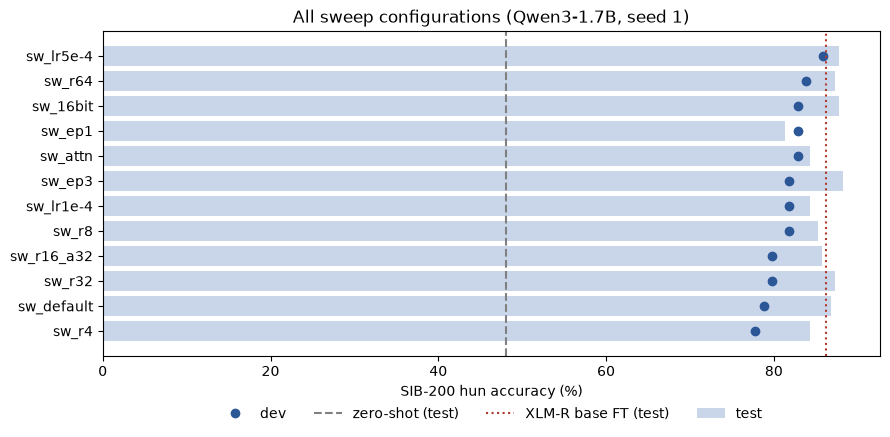

In [14]:
# Figure: accuracy of all LoRA settings

okw = sw[sw.status == "ok"]
fig, ax = plt.subplots(figsize=(9, 4.5))
o = okw.sort_values("sib_hun_dev_acc")
ax.barh(o.run_id.str.replace("qwen3-1.7b_", ""), o.sib_hun_test_acc, color="#c9d6ea", label="test")
ax.plot(o.sib_hun_dev_acc, range(len(o)), "o", color="#2b5797", label="dev")
zs = R("base_qwen3-1.7b_4bit_zs_en")
if len(zs): ax.axvline(zs.sib_hun_test_acc.iloc[0], color="gray", ls="--", label="zero-shot (test)")
if hun_m1 is not None: ax.axvline(hun_m1.test_acc.mean(), color="#b03a2e", ls=":", label="XLM-R base FT (test)")
ax.set_xlabel("SIB-200 hun accuracy (%)"); ax.set_title("All sweep configurations (Qwen3-1.7B, seed 1)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False); plt.tight_layout(); plt.savefig(PLOTS / "sweep_all.png", dpi=130, bbox_inches="tight"); plt.show()

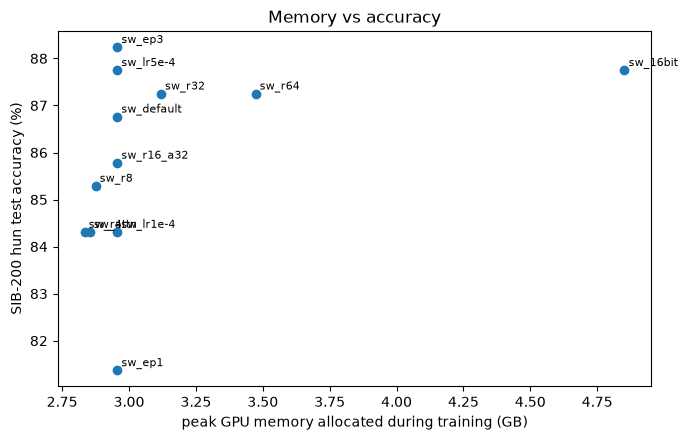

In [15]:
# Figure: GPU memory vs. accuracy

mem = okw[["run_id", "peak_mem_alloc_train_gb", "train_time_s", "trainable_params", "sib_hun_test_acc"]].copy()
mem["run"] = mem.run_id.str.replace("qwen3-1.7b_", "")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(mem.peak_mem_alloc_train_gb, mem.sib_hun_test_acc)
for _, r in mem.iterrows(): ax.annotate(r.run, (r.peak_mem_alloc_train_gb, r.sib_hun_test_acc), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("peak GPU memory allocated during training (GB)"); ax.set_ylabel("SIB-200 hun test accuracy (%)")
ax.set_title("Memory vs accuracy"); plt.tight_layout(); plt.savefig(PLOTS / "memory_vs_accuracy.png", dpi=130); plt.show()

### 6.5 Answer Format of the Untrained Model

How often the untrained model answers in the requested format when it writes freely (`gen_valid`), and how often its free answer is correct (`gen_acc`).

In [16]:
# Free-text answers of the untrained model

g = ok[ok.group == "baseline"][["run_id", "sib_hun_test_acc", "sib_hun_test_gen_acc", "sib_hun_test_gen_valid",
                                "belebele_hun_full_acc", "belebele_hun_full_gen_acc", "belebele_hun_full_gen_valid"]]
g = g.dropna(subset=["sib_hun_test_gen_acc"]); g

,run_id,sib_hun_test_acc,sib_hun_test_gen_acc,sib_hun_test_gen_valid,belebele_hun_full_acc,belebele_hun_full_gen_acc,belebele_hun_full_gen_valid
0,base_qwen3-1.7b_4bit_zs_en,48.04,37.75,0.00,38.89,50.11,0.0
1,base_qwen3-1.7b_16bit_zs_en,32.84,47.06,39.71,47.78,46.89,0.0


### 6.6 Which Topics Are Confused

Confusion matrices on the Hungarian SIB-200 test set: the model without training and the fine-tuned model (seed 1).

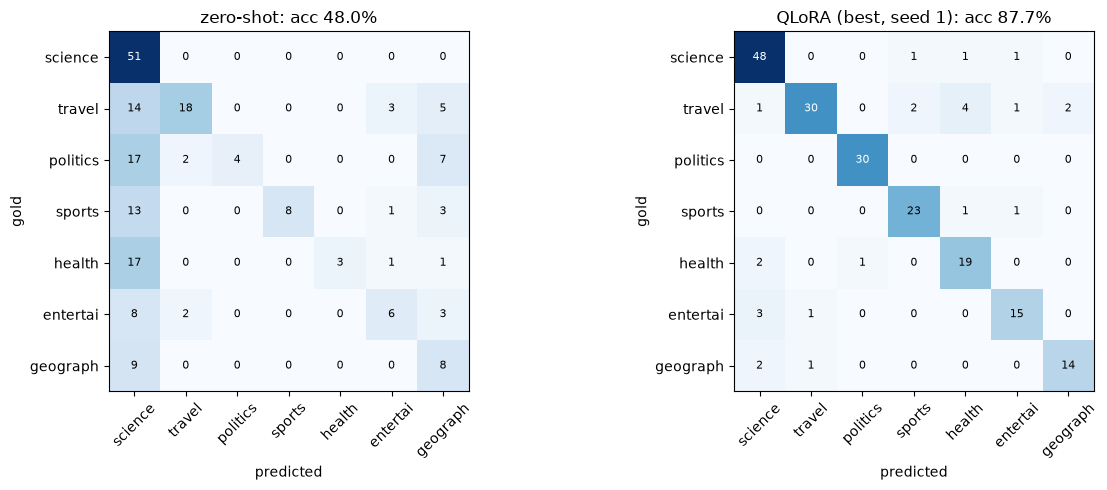

In [17]:
# Confusion matrices: without training vs. after LoRA

from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, rid, title in [(axes[0], "base_qwen3-1.7b_4bit_zs_en", "zero-shot"), (axes[1], "final_qwen3-1.7b_seed1", "QLoRA (best, seed 1)")]:
    f = m2.PRED_DIR / f"{rid}__sib_hun_Latn_test.csv"
    if not f.exists(): continue
    p = pd.read_csv(f)
    cm = confusion_matrix(p.gold, p.pred, labels=m2.SIB_LABELS)
    ax.imshow(cm, cmap="Blues")
    for i in range(7):
        for j in range(7): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
    short = [l.split("/")[0][:8] for l in m2.SIB_LABELS]
    ax.set_xticks(range(7), short, rotation=45); ax.set_yticks(range(7), short)
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(f"{title}: acc {(p.gold == p.pred).mean() * 100:.1f}%")
plt.tight_layout(); plt.savefig(PLOTS / "confusion_qwen.png", dpi=130); plt.show()

In [18]:
# Save all tables for the README

with open(m2.RESULTS_DIR / "tables.md", "w", encoding="utf-8") as f:
    for title, t in [("Milestone 1", m1_table), ("GPT reference", gpt), ("Main results", main),
                     ("Sweep", sweep_table), ("Format following", g)]:
        f.write(f"## {title}\n\n{t.to_markdown(index=False)}\n\n")
print("Saved results/tables.md")

Saved results/tables.md


## 7. Results and Conclusion

In this milestone, we tested Qwen3-1.7B on Hungarian without training and then fine-tuned it with LoRA.

Without training, the 4-bit model reached **48.0%** on the Hungarian SIB-200 test set (the 16-bit model: 32.8%). The untrained model also did not follow the answer format: it wrote full sentences instead of just the topic.

We compared 12 LoRA settings and chose the best one on the validation set: rank 16, alpha 16, all layers, 4-bit, learning rate 5e-4, 2 epochs. Trained with three seeds, it reached **87.8%** on the Hungarian test set, better than XLM-R base from Milestone 1 (**86.3%**), while training only about 1% of the model's parameters. Training took about 2 minutes and used about 3.0 GB of GPU memory.

The fine-tuned model also improved on English SIB-200 (50.5% → 91.2%) and on Hungarian Belebele (37.5% → 52.2%), although it was only trained on Hungarian topic classification.

Comparing the settings, 4-bit training (QLoRA) used 39% less memory than 16-bit with the same accuracy, and the size of the add-on (rank 4 to 64) changed the test accuracy by only about 3 percentage points. Too little training (1 epoch or a lower learning rate) was worse.

The test set is small (204 sentences, so one sentence is 0.5%), and each setting was trained only once, so small differences between settings may be random.

Overall, LoRA fine-tuning made the small model much better in Hungarian and let it beat the fully fine-tuned XLM-R baseline on a 6 GB laptop GPU.